# P06-B — Praktik Orange dan Python

Notebook ini membaca CSV yang dibuat oleh `P06A_generator_data_sintesis.ipynb`. Jalankan generator terlebih dahulu pada lingkungan yang sama, atau unggah tiga CSV dari folder `data_bab6`. Praktik menggunakan regresi, klasifikasi, dan clustering. Hasil tetap bersifat demonstrasi sintesis.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, confusion_matrix, classification_report, balanced_accuracy_score, roc_auc_score, silhouette_score, adjusted_rand_score
from sklearn.cluster import KMeans

DATA = Path("praktikum/bab06/data_bab6") if Path("praktikum/bab06").is_dir() else Path("data_bab6")
DATA.mkdir(parents=True, exist_ok=True)
expected = {"marshall_regression.csv", "pavement_priority.csv", "pavement_clustering.csv"}
if not expected.issubset({p.name for p in DATA.glob("*.csv")}):
    try:
        from google.colab import files
        print("Unggah tiga CSV hasil P06A_generator_data_sintesis.ipynb")
        uploaded = files.upload()
        for name, content in uploaded.items():
            (DATA / name).write_bytes(content)
    except ImportError:
        print("Salin tiga CSV keluaran generator ke folder data_bab6 di direktori kerja.")


## A. Regresi stabilitas Marshall

Setiap baris merupakan rancangan independen; pemisahan acak sesuai dengan pertanyaan demonstrasi ini. Pada data beberapa benda uji per batch, ganti dengan pembagian kelompok.

In [2]:
df = pd.read_csv(DATA/"marshall_regression.csv")
target = "stability_kN"
features = ["binder_pct","air_void_pct","vma_pct","aggregate_shape_index","gradation_index"]
X_train, X_test, y_train, y_test = train_test_split(df[features], df[target], test_size=0.25, random_state=SEED if "SEED" in globals() else 260616)
models = {"Linear Regression":LinearRegression(), "Decision Tree":DecisionTreeRegressor(max_depth=5, random_state=260616), "Random Forest":RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=260616)}
rows=[]
for name, model in models.items():
    model.fit(X_train,y_train)
    pred=model.predict(X_test)
    rows.append({"model":name,"MAE_kN":mean_absolute_error(y_test,pred),"RMSE_kN":mean_squared_error(y_test,pred)**0.5,"R2":r2_score(y_test,pred)})
reg_scores=pd.DataFrame(rows).sort_values("RMSE_kN")
reg_scores

,model,MAE_kN,RMSE_kN,R2
0,Linear Regression,1.809426,2.239669,0.593076
2,Random Forest,1.795685,2.337661,0.556689
1,Decision Tree,2.168395,2.741484,0.390300


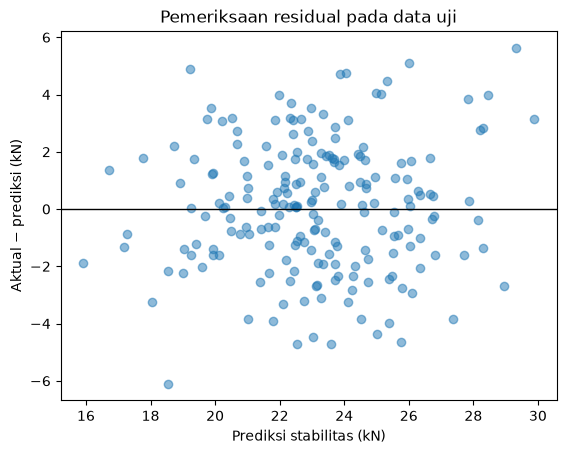

In [3]:
best = models[reg_scores.iloc[0]["model"]]
pred = best.predict(X_test)
residual = y_test.to_numpy() - pred
plt.scatter(pred, residual, alpha=.5)
plt.axhline(0, color="black", linewidth=1)
plt.xlabel("Prediksi stabilitas (kN)")
plt.ylabel("Aktual − prediksi (kN)")
plt.title("Pemeriksaan residual pada data uji")
plt.show()

## B. Klasifikasi prioritas

Gunakan stratifikasi untuk mempertahankan proporsi kelas pada demonstrasi ini. Pada data lapangan, validasi harus mencerminkan unit generalisasi, misalnya ruas, survei, atau tahun baru.

In [4]:
dfc = pd.read_csv(DATA/"pavement_priority.csv")
features_c = ["iri_m_per_km","crack_pct","rut_depth_cm","deflection_mm","adt_thousand"]
Xtr,Xte,ytr,yte=train_test_split(dfc[features_c],dfc["priority"],test_size=.25,random_state=260616,stratify=dfc["priority"])
clfs={"Logistic Regression":make_pipeline(StandardScaler(),LogisticRegression(class_weight="balanced",max_iter=2000,random_state=260616)),"Random Forest":RandomForestClassifier(n_estimators=300,min_samples_leaf=3,class_weight="balanced",random_state=260616)}
for name,model in clfs.items():
    model.fit(Xtr,ytr)
    pred=model.predict(Xte)
    proba=model.predict_proba(Xte)[:,list(model.classes_).index("tinggi")]
    print("\n",name)
    print(confusion_matrix(yte,pred,labels=["rendah","tinggi"]))
    print(classification_report(yte,pred,labels=["rendah","tinggi"],zero_division=0))
    print("Balanced accuracy:",balanced_accuracy_score(yte,pred),"ROC-AUC:",roc_auc_score((yte=="tinggi").astype(int),proba))


 Logistic Regression
[[238  11]
 [  0  51]]
              precision    recall  f1-score   support

      rendah       1.00      0.96      0.98       249
      tinggi       0.82      1.00      0.90        51

    accuracy                           0.96       300
   macro avg       0.91      0.98      0.94       300
weighted avg       0.97      0.96      0.96       300

Balanced accuracy: 0.9779116465863453 ROC-AUC: 1.0



 Random Forest
[[235  14]
 [ 10  41]]
              precision    recall  f1-score   support

      rendah       0.96      0.94      0.95       249
      tinggi       0.75      0.80      0.77        51

    accuracy                           0.92       300
   macro avg       0.85      0.87      0.86       300
weighted avg       0.92      0.92      0.92       300

Balanced accuracy: 0.8738483345145287 ROC-AUC: 0.9785809906291834


## C. Clustering profil kondisi

`synthetic_reference` tidak menjadi fitur. Skala fitur diseragamkan sebelum menghitung jarak. Silhouette dan adjusted Rand index menjawab pertanyaan yang berbeda.

In [5]:
dfk=pd.read_csv(DATA/"pavement_clustering.csv")
features_k=["iri_m_per_km","crack_pct","rut_depth_cm","deflection_mm"]
scaler=StandardScaler()
Z=scaler.fit_transform(dfk[features_k])
km=KMeans(n_clusters=3,n_init=20,random_state=260616).fit(Z)
print("Silhouette:",silhouette_score(Z,km.labels_))
print("ARI terhadap label generator (evaluasi eksternal):",adjusted_rand_score(dfk["synthetic_reference"],km.labels_))
dfk["cluster"]=km.labels_
dfk.groupby("cluster")[features_k].median().round(2)

Silhouette: 0.46637695681878183
ARI terhadap label generator (evaluasi eksternal): 0.958799772587395


,iri_m_per_km,crack_pct,rut_depth_cm,deflection_mm
cluster,,,,
0,1.71,4.13,0.37,0.45
1,5.23,24.81,1.54,1.44
2,3.22,12.32,0.87,0.85


## Diskusi

1. Apakah pemenang peringkat metrik juga menjadi model paling berguna bagi keputusan?
2. Bagaimana berubahnya recall jika ambang prioritas diturunkan?
3. Apakah clustering memberi profil yang cukup berbeda untuk ditindaklanjuti?
4. Apa yang perlu diubah sebelum menggunakan data berulang per batch atau ruas jalan?

Jangan menafsirkan angka yang dihasilkan sebagai validasi lapangan. Bandingkan hasil notebook dengan Orange setelah menyamakan target, fitur, seed, pembagian, dan metrik.